# VoltSlot - Analytics Notebook
**TCET IT: PBL + IP + PS-IV** - EV charging locator and slot-booking system.
All data is **synthetic** (seed 42). This notebook walks through the PS-IV topics on the VoltSlot data warehouse:
data cleaning verification, EDA, statistics and hypothesis tests, regression, time-series forecasting, K-Means segmentation,
text sentiment, and a business summary.

Table convention: every table printed here starts with a **Sr No** column, headers are bold and centred, numbers are right-aligned
and rupee values use Indian digit grouping (e.g. Rs 12,34,567).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
sys.path.insert(0, ".")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from common import get_conn, query, indian, inr

plt.rcParams.update({"figure.facecolor": "#0f1720", "axes.facecolor": "#0f1720", "savefig.facecolor": "#0f1720", "text.color": "#e6edf3",
    "axes.labelcolor": "#e6edf3", "xtick.color": "#9fb0c0", "ytick.color": "#9fb0c0", "axes.edgecolor": "#3a4756", "grid.color": "#243241",
    "axes.grid": True, "figure.dpi": 100})
PAL = ["#2ec4b6", "#ff9f1c", "#5aa9ff", "#e56b6f", "#b388eb", "#8bd450"]
np.random.seed(42)
conn = get_conn()

def show(df, money=(), ints=(), dec=2):
    """Org table standard: Sr No first column, bold centred headers, numbers right, text left, INR in Indian grouping."""
    d = df.reset_index(drop=True).copy()
    d.insert(0, "Sr No", range(1, len(d) + 1))
    fm = {}
    for c in d.columns[1:]:
        if c in money:
            fm[c] = lambda v: "" if pd.isna(v) else "Rs " + indian(v, 2)
        elif pd.api.types.is_numeric_dtype(d[c]) and c not in ints:
            fm[c] = (lambda v, dec=dec: "" if pd.isna(v) else (f"{v:,.0f}" if float(v).is_integer() else f"{v:,.{dec}f}"))
        elif c in ints:
            fm[c] = lambda v: "" if pd.isna(v) else f"{int(v):,}"
    num = [c for c in d.columns if pd.api.types.is_numeric_dtype(d[c])]
    txt = [c for c in d.columns if c not in num]
    sty = d.style.hide(axis="index").format(fm)
    sty = sty.set_table_styles([{"selector": "th", "props": [("text-align", "center"), ("font-weight", "bold")]}])
    sty = sty.set_properties(subset=num, **{"text-align": "right"}).set_properties(subset=txt, **{"text-align": "left"})
    from IPython.display import display
    display(sty)

## 1. Data model and row counts
Thirty OLTP tables plus the `dw_` star schema (dimensions: date, station, connector, vehicle; fact: session).

In [2]:
tabs = query("SELECT table_name AS tbl, table_rows AS approx_rows FROM information_schema.tables WHERE table_schema='chargeiq' ORDER BY table_name")
exact = []
for t in tabs["tbl"]:
    exact.append(int(query(f"SELECT COUNT(*) n FROM `{t}`")["n"][0]))
tabs = pd.DataFrame({"table": tabs["tbl"], "rows": exact})
show(tabs, ints=("rows",))

Sr No,table,rows
1,amenities,9
2,booking_slots,"46,772"
3,bookings,"9,542"
4,charging_points,103
5,charging_sessions,"7,789"
6,connector_types,5
7,demand_forecast,"5,376"
8,dw_dim_connector,5
9,dw_dim_date,457
10,dw_dim_station,32


## 2. Data cleaning (PS-IV: pre-processing)
The raw extracts (`data/raw/*_raw.csv`) were generated with realistic defects: duplicates, mixed date formats (ISO vs DD/MM/YYYY),
inconsistent spellings, trailing blanks, phone variants, swapped latitude/longitude, negative and 10x energy outliers, `N/A` / `-` tokens.
`clean_data.py` repairs them and writes a log and a cell-level verification against the clean truth.

In [3]:
D = Path("..") / "data"
log = pd.read_csv(D / "cleaning_log.csv")
ver = pd.read_csv(D / "cleaning_verification.csv")
print("Cleaning log columns:", list(log.columns))
show(log.head(25))

Cleaning log columns: ['issue_type', 'table', 'column', 'rows_fixed', 'method']


Sr No,issue_type,table,column,rows_fixed,method
1,10x outlier,bookings,est_energy_kwh,27,value > 120 kWh (no EV battery that big) divided by 10
2,duplicate rows,bookings,booking_code,139,drop_duplicates on booking_code
3,inconsistent categorical spelling,bookings,status,"1,951",mapped to canonical code
4,inconsistent categorical spelling,bookings,source,"1,542",mapped to canonical code
5,inconsistent categorical spelling,bookings,connector_type,"2,660",mapped to canonical code
6,leading/trailing spaces,bookings,booking_code,289,str.strip()
7,missing value,bookings,source,100,imputed with mode 'WEB'
8,missing value,bookings,connector_type,282,derived from charging_points.connector_type_id
9,missing value,bookings,slots,176,derived from (end_time - start_time) / 30 min
10,missing value,bookings,end_time,268,derived as start_time + slots*30 min


In [4]:
show(ver)

Sr No,table,rows_clean,rows_cleaned,rows_matched_pct,cells,cells_match,cell_match_pct,worst_columns
1,bookings,"9,283","9,283",100,"139,245","139,186",99.96,"{'source': np.float64(99.47), 'est_energy_kwh': np.float64(99.91), 'end_time': np.float64(99.99)}"
2,charging_sessions,"7,789","7,789",100,"77,890","77,748",99.82,"{'ended_at': np.float64(98.25), 'amount': np.float64(99.92), 'id': np.float64(100.0)}"
3,users,656,656,100,"5,904","5,891",99.78,"{'phone': np.float64(98.17), 'full_name': np.float64(99.85), 'email': np.float64(100.0)}"
4,stations,32,32,100,320,320,100,"{'name': np.float64(100.0), 'zone': np.float64(100.0), 'city': np.float64(100.0)}"
5,reviews,"1,718","1,718",100,"10,308","10,296",99.88,"{'rating': np.float64(99.3), 'station_id': np.float64(100.0), 'user_id': np.float64(100.0)}"


## 3. Exploratory data analysis
### 3.1 Bookings by status and by source

In [5]:
bs = query("SELECT status, COUNT(*) bookings FROM bookings GROUP BY status ORDER BY bookings DESC")
bs["share_pct"] = (bs["bookings"] / bs["bookings"].sum() * 100).round(2)
show(bs, ints=("bookings",))
src = query("SELECT source, COUNT(*) bookings, ROUND(AVG(est_cost),2) avg_est_cost FROM bookings GROUP BY source ORDER BY bookings DESC")
show(src, money=("avg_est_cost",), ints=("bookings",))

Sr No,status,bookings,share_pct
1,COMPLETED,"7,789",81.63
2,CANCELLED,704,7.38
3,NO_SHOW,446,4.67
4,EXPIRED,342,3.58
5,CONFIRMED,259,2.71
6,CHECKED_IN,2,0.02


Sr No,source,bookings,avg_est_cost
1,WEB,"5,580",Rs 327.51
2,WALK_IN,"1,616",Rs 309.44
3,FLEET,"1,567",Rs 176.34
4,REMINDER,767,Rs 329.05
5,WAITLIST,12,Rs 349.73


### 3.2 Monthly sessions, energy and revenue (growth, monsoon dip)

Sr No,month,sessions,energy_kwh,revenue
1,2025-10,628,"11,546.10","Rs 1,83,571.47"
2,2025-11,493,"8,890.30","Rs 1,34,560.94"
3,2025-12,573,"10,066","Rs 1,50,340.22"
4,2026-01,580,"10,817.80","Rs 1,69,655.90"
5,2026-02,510,"9,232.20","Rs 1,43,646.15"
6,2026-03,624,"11,673.50","Rs 1,83,516.03"
7,2026-04,698,"13,069.20","Rs 2,03,116.33"
8,2026-05,665,"12,081.20","Rs 1,89,501.48"
9,2026-06,686,"13,083.90","Rs 1,97,837.48"
10,2026-07,700,"13,143.90","Rs 2,05,586.78"


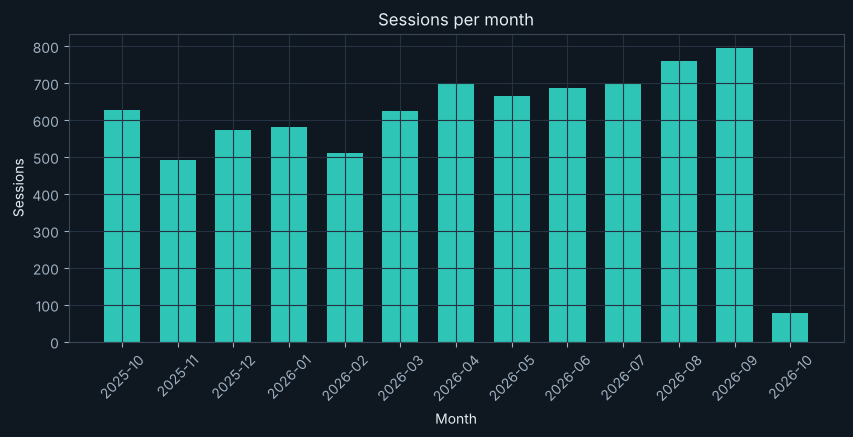

In [6]:
m = query("""SELECT d.month_key AS month, COUNT(*) sessions, ROUND(SUM(f.energy_kwh),1) energy_kwh, ROUND(SUM(f.revenue),2) revenue
              FROM dw_fact_session f JOIN dw_dim_date d ON d.date_key=f.date_key GROUP BY d.month_key ORDER BY 1""")
show(m, money=("revenue",), ints=("sessions",))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(m["month"], m["sessions"], color=PAL[0], width=.65)
ax.set_title("Sessions per month"); ax.set_xlabel("Month"); ax.set_ylabel("Sessions"); plt.xticks(rotation=45); plt.show()

### 3.3 Hour-of-day by weekday heatmap

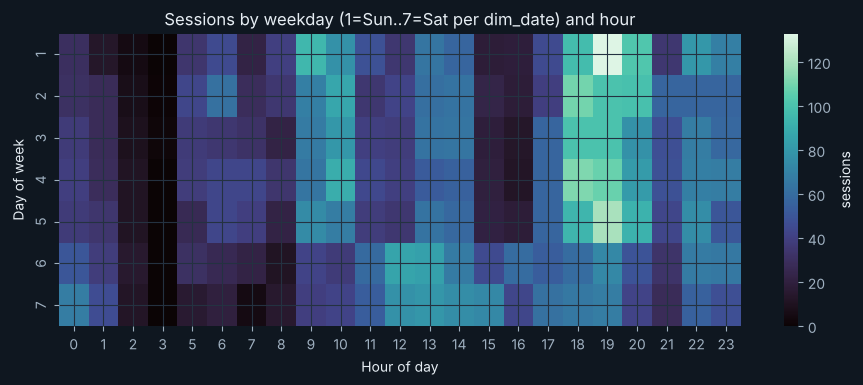

In [7]:
h = query("""SELECT d.day_of_week dow, f.time_key hr, COUNT(*) n FROM dw_fact_session f JOIN dw_dim_date d ON d.date_key=f.date_key GROUP BY 1,2""")
pv = h.pivot(index="dow", columns="hr", values="n").fillna(0)
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(pv, cmap="mako", ax=ax, cbar_kws={"label": "sessions"})
ax.set_title("Sessions by weekday (1=Sun..7=Sat per dim_date) and hour"); ax.set_xlabel("Hour of day"); ax.set_ylabel("Day of week"); plt.show()

### 3.4 Energy and duration by connector / vehicle category

In [8]:
e = query("""SELECT c.code connector, v.category, COUNT(*) sessions, ROUND(AVG(f.energy_kwh),2) avg_kwh, ROUND(AVG(f.duration_min),1) avg_min,
              ROUND(AVG(f.effective_tariff),2) avg_tariff FROM dw_fact_session f JOIN dw_dim_connector c ON c.connector_key=f.connector_key
              JOIN dw_dim_vehicle v ON v.vehicle_key=f.vehicle_key GROUP BY 1,2 ORDER BY 1,2""")
show(e, money=("avg_tariff",), ints=("sessions",))

Sr No,connector,category,sessions,avg_kwh,avg_min,avg_tariff
1,BHARAT_DC,THREE_WHEELER,249,5.81,62.8,Rs 12.11
2,CCS2,CAR,"2,464",21.62,35.5,Rs 19.75
3,CCS2,LCV,682,14.20,38.8,Rs 16.00
4,CHADEMO,CAR,43,23.28,32.7,Rs 17.71
5,LECCS,THREE_WHEELER,390,5.58,132.9,Rs 8.78
6,LECCS,TWO_WHEELER,"1,112",2.44,67.7,Rs 9.96
7,TYPE2,CAR,"2,812",25.99,305.4,Rs 12.64
8,TYPE2,LCV,37,17.34,404.0,Rs 11.52


### 3.5 Revenue by zone

Sr No,zone,sessions,revenue,energy_kwh
1,BKC,"1,083","Rs 3,71,605.97","21,428.40"
2,Powai,938,"Rs 3,07,755.63","18,336.90"
3,Andheri East,749,"Rs 2,49,644.37","14,728.80"
4,Thane West,"1,027","Rs 2,34,368.09","14,964.60"
5,Vashi,735,"Rs 1,57,345.37","10,371.60"
6,Airport,587,"Rs 1,50,539.82","9,519.70"
7,Kharghar,602,"Rs 1,34,997.61","8,769.50"
8,Lower Parel,342,"Rs 1,20,306.38","7,138.60"
9,Goregaon,198,"Rs 58,335.37","4,584.90"
10,Malad,194,"Rs 57,990.51","4,215.80"


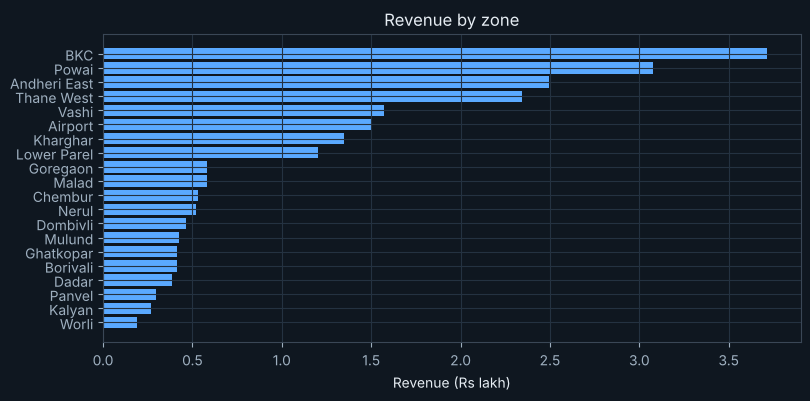

In [9]:
z = query("""SELECT s.zone, COUNT(*) sessions, ROUND(SUM(f.revenue),2) revenue, ROUND(SUM(f.energy_kwh),1) energy_kwh
              FROM dw_fact_session f JOIN dw_dim_station s ON s.station_key=f.station_key GROUP BY 1 ORDER BY revenue DESC""")
show(z, money=("revenue",), ints=("sessions",))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(z["zone"][::-1], z["revenue"][::-1].astype(float) / 1e5, color=PAL[2]); ax.set_xlabel("Revenue (Rs lakh)"); ax.set_title("Revenue by zone"); plt.show()

## 4. Descriptive statistics and correlation

Sr No,variable,count,mean,std,min,25%,50%,75%,max
1,energy_kwh,"7,789",18.49,11.27,0.64,10.17,17.74,26.42,58.53
2,duration_min,"7,789",145.28,139.97,7,37,69,253,674
3,revenue,"7,789",286.92,198.01,6.30,141.95,274.75,409.83,"1,284.62"
4,effective_tariff,"7,789",14.61,4.44,7.65,11,13.50,18,28.80
5,lead_time_hours,"7,789",21.35,32.51,0,3.13,13.48,21.43,167.92
6,soc_start,"7,789",27.24,10.64,8,19,26,36,50
7,soc_end,"7,789",87.51,9.58,50,80,90,90,100


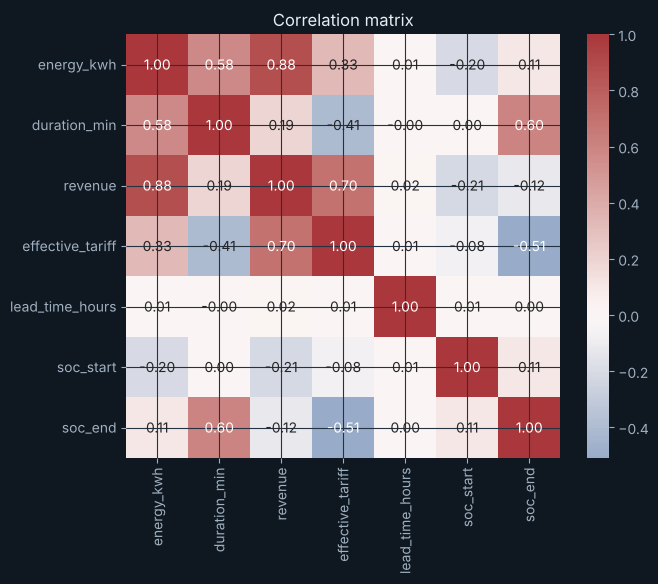

In [10]:
fs = query("SELECT energy_kwh, duration_min, revenue, effective_tariff, lead_time_hours, soc_start, soc_end FROM dw_fact_session").astype(float)
desc = fs.describe().T.reset_index().rename(columns={"index": "variable"})
show(desc.round(2))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(fs.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax); ax.set_title("Correlation matrix"); plt.show()

Energy, duration and revenue are strongly positively correlated (a longer charge delivers more kWh and costs more); `soc_start` is negatively correlated with energy delivered (a lower start state-of-charge leaves more room to charge).

## 5. Hypothesis tests
### 5.1 Is weekend demand different from weekday demand? (Welch t-test on daily sessions)

In [11]:
daily = query("""SELECT d.full_date dt, d.is_weekend wk, d.is_holiday hol, d.weather_label wx, COUNT(*) n
                 FROM dw_fact_session f JOIN dw_dim_date d ON d.date_key=f.date_key GROUP BY 1,2,3,4 ORDER BY 1""")
daily["dt"] = pd.to_datetime(daily["dt"])
a = daily.loc[daily.wk == 1, "n"].astype(float); b = daily.loc[daily.wk == 0, "n"].astype(float)
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"Weekend mean {a.mean():.1f} vs weekday mean {b.mean():.1f} sessions/day;  Welch t = {t:.2f},  p = {p:.4g}")
print("Reject H0 (equal means) at 5%" if p < .05 else "Fail to reject H0 at 5%")

Weekend mean 20.0 vs weekday mean 21.6 sessions/day;  Welch t = -2.01,  p = 0.04555
Reject H0 (equal means) at 5%


### 5.2 Does the connector type change energy per session? (one-way ANOVA)

In [12]:
g = query("SELECT c.code, f.energy_kwh FROM dw_fact_session f JOIN dw_dim_connector c ON c.connector_key=f.connector_key")
groups = [x["energy_kwh"].astype(float).values for _, x in g.groupby("code") if len(x) > 5]
F, p = stats.f_oneway(*groups)
print(f"ANOVA over {len(groups)} connector types: F = {F:.2f}, p = {p:.4g}")

ANOVA over 5 connector types: F = 2460.61, p = 0


### 5.3 Is rating independent of sentiment label? (chi-square test of independence)

In [13]:
r = query("SELECT rating, sentiment_label FROM reviews WHERE sentiment_label IS NOT NULL")
ct = pd.crosstab(r["rating"], r["sentiment_label"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"chi2 = {chi2:.1f}, dof = {dof}, p = {p:.3g}  -> rating and sentiment are strongly associated")
show(ct.reset_index())

chi2 = 771.1, dof = 8, p = 3.45e-161  -> rating and sentiment are strongly associated


Sr No,rating,NEGATIVE,NEUTRAL,POSITIVE
1,1,10,1,0
2,2,38,12,3
3,3,141,97,65
4,4,49,146,534
5,5,8,37,577


## 6. Regression
### 6.1 Rain vs daily sessions (OLS, detrended)
Raw OLS of sessions on rainfall is confounded by network growth, so we detrend with a linear time term and a weekend dummy.

In [14]:
w = query("SELECT weather_date dt, rainfall_mm, avg_temp_c FROM weather_daily")
w["dt"] = pd.to_datetime(w["dt"])
df = daily.merge(w, on="dt", how="left")
df["t"] = np.arange(len(df)); df["rain"] = df["rainfall_mm"].astype(float)
X = sm.add_constant(df[["t", "wk", "rain"]].astype(float)); mod = sm.OLS(df["n"].astype(float), X).fit()
print(mod.summary().tables[1])
print(f"R-squared = {mod.rsquared:.3f}")
idx = df.groupby("wx")["n"].mean()
print("Mean daily sessions by weather label:\n", idx.round(2).to_string())

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         17.1759      0.739     23.228      0.000      15.722      18.630
t              0.0260      0.003      7.449      0.000       0.019       0.033
wk            -1.7024      0.782     -2.178      0.030      -3.240      -0.165
rain          -0.0418      0.019     -2.237      0.026      -0.079      -0.005
R-squared = 0.141
Mean daily sessions by weather label:
 wx
CLEAR         19.86
CLOUDY        21.71
HEAVY_RAIN    20.85
RAIN          25.26


### 6.2 Energy delivered from duration and start state-of-charge

In [15]:
d2 = fs.dropna()
X = sm.add_constant(d2[["duration_min", "soc_start"]]); m2 = sm.OLS(d2["energy_kwh"], X).fit()
print(m2.summary().tables[1]); print(f"R-squared = {m2.rsquared:.3f}")

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           17.7175      0.297     59.730      0.000      17.136      18.299
duration_min     0.0464      0.001     64.245      0.000       0.045       0.048
soc_start       -0.2191      0.010    -23.066      0.000      -0.238      -0.201
R-squared = 0.374


## 7. Time-series forecasting (Holt-Winters)
`forecast.py` fits additive damped-trend Holt-Winters with weekly seasonality per zone, back-tests on the last 28 days, and stores 42-day forecasts in `network_forecast`.

Sr No,zone,model,MAE,RMSE,MAPE_pct
1,ALL,"Holt-Winters (damped, w=7)",6.35,7.62,26.21
2,ALL,Seasonal naive (t-7),11.11,13.93,47.09
3,ALL,7-day moving average,6.18,7.33,26.09
4,BKC,"Holt-Winters (damped, w=7)",1.44,1.78,39.59
5,BKC,Seasonal naive (t-7),2.29,2.75,62.31
6,BKC,7-day moving average,1.39,1.73,39.22
7,Thane West,"Holt-Winters (damped, w=7)",1.35,1.60,46.76
8,Thane West,Seasonal naive (t-7),1.93,2.30,74.01
9,Thane West,7-day moving average,1.28,1.51,46.24
10,Powai,"Holt-Winters (damped, w=7)",1.23,1.48,42.90


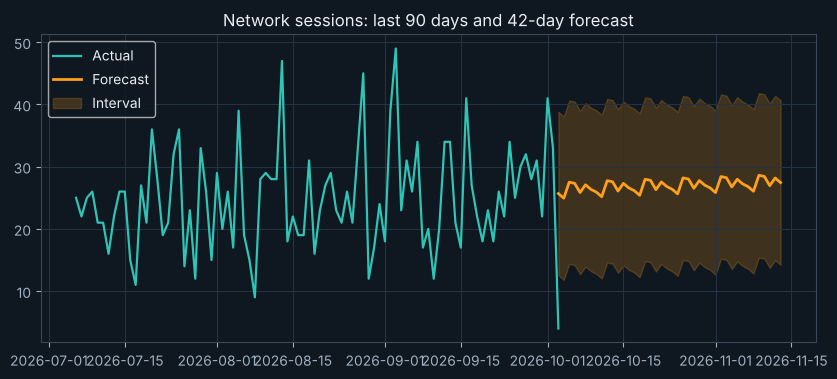

In [16]:
ev = pd.read_csv(D.parent / "analytics" / "reports" / "forecast_eval.csv") if (D.parent / "analytics" / "reports" / "forecast_eval.csv").exists() else pd.read_csv("reports/forecast_eval.csv")
show(ev.round(3))
nf = query("SELECT forecast_date dt, predicted_sessions, lower_bound, upper_bound FROM network_forecast WHERE zone='ALL' ORDER BY 1")
hist = daily.groupby("dt")["n"].sum().tail(90)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist.index, hist.values, color=PAL[0], lw=1.6, label="Actual")
nf["dt"] = pd.to_datetime(nf["dt"])
ax.plot(nf["dt"], nf["predicted_sessions"].astype(float), color=PAL[1], lw=2, label="Forecast")
ax.fill_between(nf["dt"], nf["lower_bound"].astype(float), nf["upper_bound"].astype(float), color=PAL[1], alpha=.2, label="Interval")
ax.set_title("Network sessions: last 90 days and 42-day forecast"); ax.legend(); plt.show()

## 8. Segmentation (K-Means)
Users are clustered on usage features (standardised); k chosen by silhouette. Stations are clustered similarly.

In [17]:
sg = query("SELECT segment_label, COUNT(*) users, ROUND(AVG(sessions_12m),1) avg_sessions, ROUND(AVG(avg_energy_kwh),1) avg_kwh, ROUND(AVG(night_share)*100,1) night_pct, ROUND(AVG(weekend_share)*100,1) weekend_pct, ROUND(AVG(total_spend),2) avg_spend FROM user_segments GROUP BY 1 ORDER BY users DESC")
show(sg, money=("avg_spend",), ints=("users",))
sil = pd.read_csv("reports/silhouette_scores.csv")
show(sil.round(3))
sc = query("SELECT cluster_label, COUNT(*) stations, ROUND(AVG(avg_daily_sessions),2) avg_daily, ROUND(AVG(revenue_12m),2) avg_revenue FROM station_clusters GROUP BY 1 ORDER BY stations DESC")
show(sc, money=("avg_revenue",), ints=("stations",))

Sr No,segment_label,users,avg_sessions,avg_kwh,night_pct,weekend_pct,avg_spend
1,Weekend Explorers,187,6.9,25.20,1,69.10,"Rs 2,652.75"
2,Occasional Chargers,138,3.8,23.10,2.30,10.40,"Rs 1,438.63"
3,Night Chargers,92,9.4,25.70,93.30,33.50,"Rs 2,754.36"
4,Light-EV Riders,86,17.3,5.60,1.60,20.50,"Rs 1,072.29"
5,Daily Commuters,80,26.5,25,0.80,10.20,"Rs 11,587.58"
6,Dormant Users,57,0.5,6.50,3.50,3.50,Rs 179.59
7,Fleet & Logistics,6,246.7,11.70,55.50,23,"Rs 42,895.63"


Sr No,k,silhouette
1,3,0.24
2,4,0.39
3,5,0.38
4,6,0.41
5,7,0.41


Sr No,cluster_label,stations,avg_daily,avg_revenue
1,Under-utilised,13,0.15,"Rs 15,506.34"
2,High-demand hub,7,2.24,"Rs 2,29,465.27"
3,Emerging,6,0.33,"Rs 38,478.69"
4,Steady performer,6,0.28,"Rs 32,686.32"


## 9. Review sentiment (TextBlob)

In [18]:
sn = query("SELECT sentiment_label, COUNT(*) reviews, ROUND(AVG(rating),2) avg_rating, ROUND(AVG(sentiment_score),3) avg_polarity FROM reviews GROUP BY 1 ORDER BY reviews DESC")
show(sn, ints=("reviews",))
kw = query("SELECT word, freq FROM sentiment_keywords ORDER BY freq DESC LIMIT 15")
show(kw, ints=("freq",))

Sr No,sentiment_label,reviews,avg_rating,avg_polarity
1,POSITIVE,"1,179",4.43,0.35
2,NEUTRAL,293,3.70,0.05
3,NEGATIVE,246,3.03,-0.29


Sr No,word,freq
1,great,329
2,charging,322
3,parking,308
4,worked,306
5,app,293
6,easy,281
7,payment,254
8,charger,246
9,well,234
10,booking,217


## 10. Booking funnel and lead time

Sr No,event_type,journeys,pct_of_search
1,SEARCH,"12,826",100
2,VIEW_STATION,"11,657",90.90
3,SELECT_SLOT,"10,007",78
4,BOOK,"7,584",59.10
5,CHECK_IN,"6,175",48.10
6,COMPLETE,"6,173",48.10


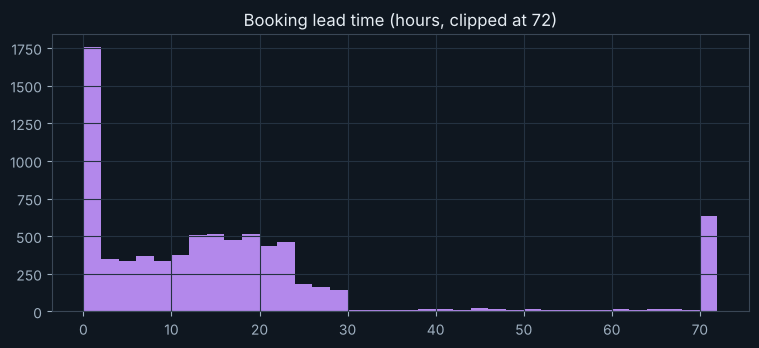

median lead time 13.5 h, mean 21.3 h


In [19]:
fn = query("SELECT event_type, COUNT(DISTINCT session_key) journeys FROM funnel_events GROUP BY 1")
order = ["SEARCH", "VIEW_STATION", "SELECT_SLOT", "BOOK", "CHECK_IN", "COMPLETE"]
fn = fn.set_index("event_type").reindex(order).reset_index()
fn["pct_of_search"] = (fn["journeys"] / fn["journeys"].iloc[0] * 100).round(1)
show(fn, ints=("journeys",))
lt = query("SELECT lead_time_hours FROM dw_fact_session").astype(float)["lead_time_hours"]
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.hist(lt.clip(upper=72), bins=36, color=PAL[4]); ax.set_title("Booking lead time (hours, clipped at 72)"); plt.show()
print(f"median lead time {lt.median():.1f} h, mean {lt.mean():.1f} h")

## 11. Business summary

In [20]:
k = query("""SELECT COUNT(*) sessions, SUM(energy_kwh) kwh, SUM(revenue) revenue, SUM(co2_avoided_kg) co2 FROM dw_fact_session""").astype(float).iloc[0]
print(f"Sessions: {int(k.sessions):,}")
print(f"Energy delivered: {k.kwh:,.0f} kWh")
print(f"Revenue: Rs {indian(k.revenue, 2)}")
print(f"CO2 avoided: {k.co2:,.0f} kg")

Sessions: 7,789
Energy delivered: 144,018 kWh
Revenue: Rs 22,34,829.34
CO2 avoided: 117,135 kg


**Findings.** Demand grows through the year with a monsoon dip; weekday demand is modestly higher than weekend demand (commuter and fleet use dominate); evening peaks at office hubs drive crowding;
a small set of stations carries most revenue (Pareto); DC fast connectors deliver more energy per session; reviews are mostly positive and
cluster around reliability, price and waiting time. These patterns are what the booking system's slot suggestion, crowding forecast and
recharge reminders exploit.